# Local model benchmark: Random Forest, boosted trees and Transformer

Train fresh local models on the **same April-June 2025 development fold**, using the current shared 29 features, then benchmark on this machine. The final holdout is excluded. These are new fits: their metrics need not reproduce previously published runs, especially the Transformer with a different recorded feature-source hash.

Start with `QUICK_RUN = True` to verify the pipeline. Quick mode uses 20,000 common training endpoints, two validation days, 25 RF trees, 30 boosting iterations and one Transformer epoch. Full mode uses the established 2-million-endpoint cap, the complete validation quarter, 300 RF/boosting trees and ten Transformer epochs. Only full runs support a representative comparison.

Training and inference use separate subprocesses for each model, with a common CPU thread limit. Checkpoints, predictions and large input fixtures remain local; compact benchmark tables are saved separately from the shared team summary. **Run all cells in order.** Full CPU training can take substantial time. Interrupting the worker cell terminates its active subprocess.


In [1]:
from pathlib import Path
import sys, os, json, time, hashlib, platform, importlib.metadata, importlib.util
from datetime import datetime
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p/'notebooks/safeflow_features.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run from inside the SafeFlow repository')
sys.path[:0] = [str(ROOT),str(ROOT/'notebooks')]
QUICK_RUN = False
CPU_THREADS = min(4, os.cpu_count() or 1)
RUN_MISSING_FEATURE_TESTS = True  # optional feature-level stress diagnostic, explained below
ALERT_THRESHOLD = 0.5             # fixed diagnostic threshold; does not equalize warning burden
TRAIN_CAP = 20_000 if QUICK_RUN else 2_000_000
LATENCY_REPETITIONS = 30 if QUICK_RUN else 200
WARMUP_BATCHES = 5 if QUICK_RUN else 20
SEED = 0
MODELS = ['random_forest','boosted_trees','transformer']
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT = ROOT/'results/local_model_benchmark'/RUN_ID
INPUTS = OUT/'inputs'
DATA_DIR = next((p for p in [ROOT/'data',ROOT/'Data'] if p.is_dir()),None)
assert CPU_THREADS >= 1
print('Mode:', 'QUICK PIPELINE CHECK' if QUICK_RUN else 'FULL LAST-FOLD BENCHMARK')
print('CPU threads:',CPU_THREADS,'| output:',OUT)


Mode: FULL LAST-FOLD BENCHMARK
CPU threads: 4 | output: C:\Erdos\Project\safeflow\results\local_model_benchmark\20261104_115016_080613


## Environment and reproducibility

Install optional benchmark dependencies in the notebook's selected kernel if needed:

```text
python -m pip install -r requirements-benchmark.txt
```

Workers use `sys.executable`, so they run in that same environment. No packages are installed automatically. Thread settings are applied before worker imports. This is a CPU comparison; no GPU results are mixed into it.


In [2]:
required={'numpy':'numpy','pandas':'pandas','pyarrow':'pyarrow','matplotlib':'matplotlib',
          'sklearn':'scikit-learn','torch':'torch','psutil':'psutil','joblib':'joblib','threadpoolctl':'threadpoolctl'}
missing=[package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    raise ImportError('Install benchmark dependencies in this kernel: '+', '.join(missing)+'. See requirements-benchmark.txt.')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
from IPython.display import display
import safeflow_features as sf
from src.random_forest import random_forest_training as rf_training
from src.transformer.build_history_windows import HistoryIndex
assert DATA_DIR is not None, 'Expected the repository data folder'
assert len(sf.SHARED_FEATURES)==29, 'Review feature changes before running this 29-feature comparison'
INPUTS.mkdir(parents=True,exist_ok=True)
(OUT.parent/'.gitignore').write_text('*/inputs/\n',encoding='utf-8')
versions={package:importlib.metadata.version(package) for package in required.values()}
source_paths=[Path(sf.__file__),ROOT/'src/analysis/local_benchmark.py',
              ROOT/'src/random_forest/safeflow_random_forest.py',ROOT/'src/random_forest/random_forest_training.py',
              ROOT/'src/boosted_trees/boosted_trees_training.py',ROOT/'src/transformer/transformer_training.py',
              ROOT/'src/transformer/safeflow_transformer.py',ROOT/'src/transformer/build_history_windows.py']
sources={str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in source_paths}
host=dict(platform=platform.platform(),processor=platform.processor(),logical_cpus=os.cpu_count(),
          physical_cpus=psutil.cpu_count(logical=False),ram_bytes=psutil.virtual_memory().total,
          python=sys.version,executable=sys.executable,versions=versions)
print('Dependencies ready. Physical RAM (GiB):',round(host['ram_bytes']/2**30,1))


Dependencies ready. Physical RAM (GiB): 15.7


## Shared training and evaluation inputs

Build or reuse the fingerprinted development cache. Typical congestion and anomaly features are calculated from this fold's training period only. Every model receives the same sampled training endpoints and the same validation endpoints. Training samples retain one common deterministic order.

Quick mode reduces model fitting, but first-time shared data loading can still be expensive. All required historical feature vectors are retained for the Transformer; missing periods split history runs and are padded using its established implementation. The input fixture contains only the fields required by the models and scoring, rather than the full raw dataset.


In [3]:
started=time.perf_counter()
df,dataset_signature=rf_training.load_dataset(sf,DATA_DIR,use_cache=True)
df=df.sort_values(sf.KEY).reset_index(drop=True)
assert df.timestamp.max()<pd.Timestamp('2025-07-01')
fold=next(sf.folds(df,only_last=True))
assert fold.name=='2025-04 to 2025-06'
sf.add_typical_features(df,fold.train)
train_candidates=np.flatnonzero((fold.train & df.y_known).to_numpy())
train_rows=pd.Series(train_candidates).sample(min(TRAIN_CAP,len(train_candidates)),random_state=SEED).to_numpy()
val_rows=np.flatnonzero(fold.val.to_numpy())
if QUICK_RUN:
    quick_days=sorted(df.iloc[val_rows].date.unique())[:2]
    val_rows=val_rows[df.iloc[val_rows].date.isin(quick_days).to_numpy()]
assert not np.intersect1d(train_rows,val_rows).size
assert df.iloc[train_rows].window_end.max()<pd.Timestamp('2025-04-01')-pd.Timedelta(days=sf.GAP_DAYS)
# Compact the frame while preserving all lookback vectors used by either endpoint set.
index=HistoryIndex(df)
endpoints=np.r_[train_rows,val_rows]
keep=np.zeros(len(df),dtype=bool)
for lag in range(24):
    keep[np.maximum(index.run_start[endpoints],endpoints-lag)]=True
old_positions=np.flatnonzero(keep)
remap=np.full(len(df),-1,dtype=np.int64)
remap[old_positions]=np.arange(len(old_positions))
columns=list(dict.fromkeys(sf.KEY+['date','y','y_known','real','congested_now','onset']+list(sf.SHARED_FEATURES)))
frame=df.loc[keep,columns].reset_index(drop=True)
train_rows=remap[train_rows];val_rows=remap[val_rows]
assert (train_rows>=0).all() and (val_rows>=0).all()
frame.to_parquet(INPUTS/'development_frame.parquet',index=False)
np.save(INPUTS/'train_rows.npy',train_rows);np.save(INPUTS/'val_rows.npy',val_rows)
# Benchmark on complete station/time rows from fixed validation days.
fixture_days=sorted(frame.iloc[val_rows].date.unique())[:(2 if QUICK_RUN else 5)]
fixture_endpoints=val_rows[frame.iloc[val_rows].date.isin(fixture_days).to_numpy()]
fixture_keep=np.zeros(len(frame),dtype=bool)
compact_index=HistoryIndex(frame)
for lag in range(24):
    fixture_keep[np.maximum(compact_index.run_start[fixture_endpoints],fixture_endpoints-lag)]=True
fixture_positions=np.flatnonzero(fixture_keep)
fixture_map=np.full(len(frame),-1,dtype=np.int64);fixture_map[fixture_positions]=np.arange(len(fixture_positions))
fixture=frame.loc[fixture_keep].reset_index(drop=True)
fixture_rows=fixture_map[fixture_endpoints]
assert len(fixture_rows)>=46
fixture.to_parquet(INPUTS/'inference_fixture.parquet',index=False)
np.save(INPUTS/'fixture_rows.npy',fixture_rows)
preparation_seconds=time.perf_counter()-started
print('Fold:',fold.name,'| training endpoints:',len(train_rows),'| validation:',len(val_rows))
print('Inference fixture endpoints:',len(fixture_rows),'| shared preparation seconds:',round(preparation_seconds,1))
del df,index,compact_index,frame,fixture,keep,remap,fixture_map,old_positions,endpoints
import gc
gc.collect()


Loading matching local development cache: C:\Erdos\Project\safeflow\src\random_forest\cache\development_343e4e0462efaa0f.parquet
Fold: 2025-04 to 2025-06 | training endpoints: 2000000 | validation: 486864
Inference fixture endpoints: 38640 | shared preparation seconds: 16.3


In [4]:
def input_hash(path):
    digest=hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda:stream.read(1024*1024),b''):
            digest.update(block)
    return digest.hexdigest()

model_dirs={m:str(ROOT/'src'/m/'results'/('local_benchmark_'+RUN_ID)/'2025-04') for m in MODELS}
for directory in model_dirs.values():
    path=Path(directory);path.mkdir(parents=True,exist_ok=True)
    # These are local fitted checkpoints, not team prediction publications.
    (path.parent/'.gitignore').write_text('*\n!.gitignore\n',encoding='utf-8')
config=dict(root=str(ROOT),quick=QUICK_RUN,threads=CPU_THREADS,features=list(sf.SHARED_FEATURES),
    frame=str(INPUTS/'development_frame.parquet'),train_rows=str(INPUTS/'train_rows.npy'),val_rows=str(INPUTS/'val_rows.npy'),
    fixture=str(INPUTS/'inference_fixture.parquet'),fixture_rows=str(INPUTS/'fixture_rows.npy'),model_dirs=model_dirs,
    warmup=WARMUP_BATCHES,repetitions=LATENCY_REPETITIONS,threshold=ALERT_THRESHOLD,
    missing_feature_tests=RUN_MISSING_FEATURE_TESTS)
CONFIG_FILE=OUT/'worker_config.json'
CONFIG_FILE.write_text(json.dumps(config,indent=2),encoding='utf-8')
manifest=dict(status='prepared',quick_run=QUICK_RUN,fold=fold.name,holdout_used=False,
    dataset_signature=dataset_signature,features=list(sf.SHARED_FEATURES),source_hashes=sources,host=host,
    config=config,shared_preparation_seconds=preparation_seconds,train_rows=len(train_rows),validation_rows=len(val_rows),
    fixture_endpoints=len(fixture_rows),sampling_seed=SEED,
    predictive_metrics='fresh fits; fixed 0.5 diagnostic threshold, not matched warning burden',
    missingness_scope='optional engineered-feature stress; not raw detector outages',
    input_sha256={p.name:input_hash(p) for p in INPUTS.iterdir() if p.is_file()})
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')


## Train and benchmark in separate processes

Each model is trained once, then loaded in a fresh inference process. The checkpoint must reproduce its saved fixture predictions before latency is measured. The worker log and periodic heartbeats show progress. CPU, disk and background-system load can affect measurements; avoid running other training jobs simultaneously.

Training time below includes fitting, validation prediction and saving, with input loading reported separately. Model-only latency includes model-specific preprocessing already inside a pipeline (RF) but excludes Transformer encoding, which is reported separately. Compare **fixture encode/build/predict time** as well as model-only latency. Raw traffic-to-feature extraction is shared and is not measured per model.

Batches of 1 and 46 use identical seeded endpoint samples for each model. They measure batch-size scaling; they are not a synchronized live corridor replay. Fresh-process memory is absolute RSS, with a baseline recorded, and includes fixture data and optional stress tests. It is not just fitted-model memory.


In [5]:
import subprocess

def run_worker(model,stage):
    environment=os.environ.copy()
    for variable in ['OMP_NUM_THREADS','MKL_NUM_THREADS','OPENBLAS_NUM_THREADS','NUMEXPR_NUM_THREADS']:
        environment[variable]=str(CPU_THREADS)
    environment['PYTHONIOENCODING']='utf-8'
    log=OUT/f'{model}_{stage}.log'
    command=[sys.executable,'-u','-m','src.analysis.local_benchmark','--config',str(CONFIG_FILE),'--model',model,'--stage',stage]
    print('Starting:',model,stage,flush=True)
    started=time.monotonic();last_heartbeat=started;offset=0
    with log.open('w',encoding='utf-8') as stream:
        process=subprocess.Popen(command,cwd=ROOT,env=environment,stdout=stream,stderr=subprocess.STDOUT)
        try:
            while True:
                text=log.read_text(encoding='utf-8',errors='replace')
                if len(text)>offset:
                    print(text[offset:],end='',flush=True);offset=len(text)
                if process.poll() is not None:break
                if time.monotonic()-last_heartbeat>=30:
                    print(f'  {model} {stage} still running: {time.monotonic()-started:.0f}s',flush=True)
                    last_heartbeat=time.monotonic()
                time.sleep(2)
        except BaseException:
            process.terminate()
            try:process.wait(timeout=10)
            except subprocess.TimeoutExpired:process.kill();process.wait()
            raise
    if process.returncode:
        raise RuntimeError(f'{model} {stage} failed; see {log}')

for model in MODELS:
    run_worker(model,'train')
    run_worker(model,'inference')
print('All local workers completed.')


Starting: random_forest train
train random_forest PID 9676
  fitting 2,000,000 rows / 29 logical features
  random_forest train still running: 30s
  random_forest train still running: 60s
  random_forest train still running: 90s
  random_forest train still running: 120s
  random_forest train still running: 150s
  random_forest train still running: 180s
  random_forest train still running: 210s
  random_forest train still running: 240s
  fit complete in 238.4s; predicting 486,864 rows
Training complete: random_forest
Starting: random_forest inference
inference random_forest PID 73476
C:\Erdos\Project\safeflow\notebooks\safeflow_features.py:555: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return found.fillna(False).astype(bool).to_numpy()
  random_forest inference still

## Comparison tables and visuals

AP describes ranking quality on the common validation population. Warning metrics at 0.5 are diagnostics: the same score threshold does not create equal warning burden. These new fits use the current feature source and may differ from historical publications. Quick-mode metrics must not be used to select the final model.

The optional feature stress test masks predefined engineered-feature families at 11:00 for 5/15/30 minutes on each fixture day, keeps outcomes fixed, and uses the original fitted preprocessing. It tests response to missing feature inputs. It does **not** causally recompute every dependent feature from missing raw detector measurements, so it is not a validated physical detector-outage experiment.


,model,AP_onsets,threshold,caught ≥15 min,false alarms / day,wrong-alert hours / day,alerts right,median lead (min),onsets
0,random_forest,0.7509,0.5,0.4987,29.0952,4.1521,0.9273,15.0,1536
1,boosted_trees,0.7669,0.5,0.6087,30.2857,4.5952,0.9214,20.0,1536
2,transformer,0.7713,0.5,0.6680,30.9841,5.1667,0.9133,25.0,1536


,model,load_seconds,fit_predict_save_seconds,peak_rss_bytes
0,random_forest,0.295406,245.917241,2788241408
1,boosted_trees,0.304128,48.446405,2535432192
2,transformer,0.289083,7800.379298,1996058624


,model,checkpoint_bytes,checkpoint_load_seconds,fixture_encode_build_predict_seconds,max_reproduction_error,peak_rss_bytes
0,random_forest,20851807,2.019624,3.995043,5.551115e-16,386850816
1,boosted_trees,495546,1.731292,0.498955,0.000000e+00,310784000
2,transformer,298620,0.038538,2.033349,0.000000e+00,510541824


,model,batch_size,scope,median_ms,p95_ms,endpoints_per_second,repetitions
0,random_forest,1,model_only,38.051,49.347,23.706,200
1,random_forest,1,batch_build_plus_model,38.246,49.656,23.584,200
2,random_forest,1,batch_build,0.202,0.365,4577.340,200
3,random_forest,46,model_only,47.589,49.174,960.504,200
4,random_forest,46,batch_build_plus_model,47.827,49.476,955.722,200
5,random_forest,46,batch_build,0.214,0.436,191993.047,200
6,boosted_trees,1,model_only,2.731,3.825,342.237,200
7,boosted_trees,1,batch_build_plus_model,2.850,3.975,328.768,200
8,boosted_trees,1,batch_build,0.104,0.197,8353.905,200
9,boosted_trees,46,model_only,2.888,4.343,14476.275,200


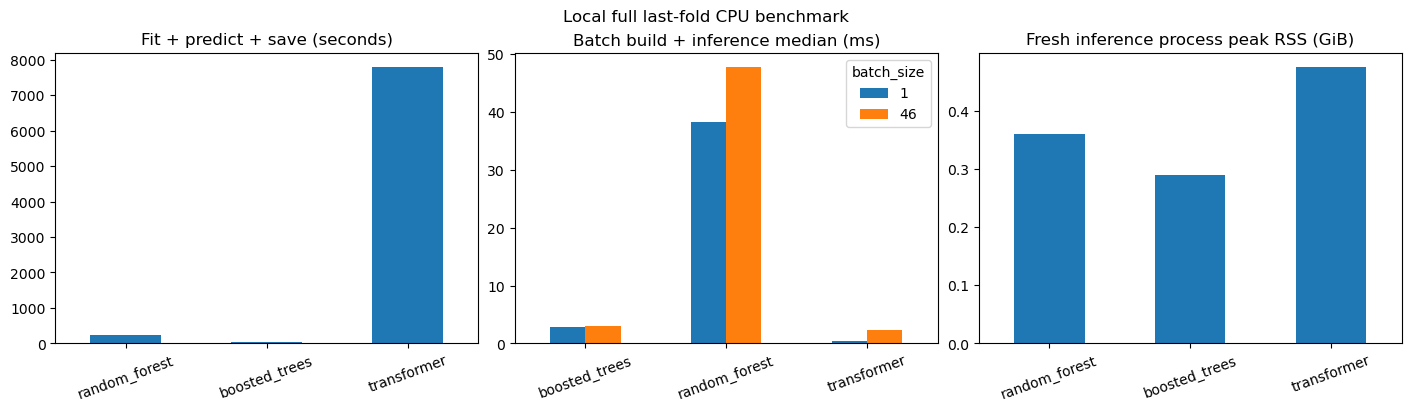

,model,scenario,AP_onsets,threshold,caught ≥15 min,false alarms / day,wrong-alert hours / day,alerts right,median lead (min),onsets
0,random_forest,clean,0.7599,0.5,0.6441,30.6,5.2500,0.9030,20.0,118
1,random_forest,current_missing_features_5min,0.7604,0.5,0.6441,30.4,5.2333,0.9033,20.0,118
2,random_forest,current_missing_features_15min,0.7605,0.5,0.6441,30.4,5.2333,0.9033,20.0,118
3,random_forest,current_missing_features_30min,0.7605,0.5,0.6441,30.4,5.2333,0.9033,20.0,118
4,random_forest,upstream_missing_features_5min,0.7600,0.5,0.6441,30.6,5.2500,0.9030,20.0,118
5,random_forest,upstream_missing_features_15min,0.7600,0.5,0.6441,30.6,5.2500,0.9030,20.0,118
6,random_forest,upstream_missing_features_30min,0.7600,0.5,0.6441,30.6,5.2500,0.9030,20.0,118
7,random_forest,downstream_missing_features_5min,0.7602,0.5,0.6441,30.6,5.2500,0.9030,20.0,118
8,random_forest,downstream_missing_features_15min,0.7602,0.5,0.6441,30.6,5.2500,0.9030,20.0,118
9,random_forest,downstream_missing_features_30min,0.7602,0.5,0.6441,30.6,5.2500,0.9030,20.0,118


Saved local benchmark: C:\Erdos\Project\safeflow\results\local_model_benchmark\20261104_115016_080613
Team summary and final holdout were not modified.


In [6]:
training=[];inference=[];latencies=[];stress=[];quality=[]
for model,directory in model_dirs.items():
    directory=Path(directory)
    training.append(json.loads((directory/'training_benchmark.json').read_text()))
    inference.append(json.loads((directory/'inference_benchmark.json').read_text()))
    latencies.append(pd.read_csv(directory/'latency.csv'))
    stress.append(pd.read_csv(directory/'feature_stress.csv'))
    prediction=pd.read_parquet(directory/'validation_predictions.parquet')
    p=prediction.probability.to_numpy()
    quality.append(dict(model=model,AP_onsets=sf.ap_onsets(prediction,p),threshold=ALERT_THRESHOLD,
                        **sf.alert_metrics(prediction,p,ALERT_THRESHOLD)))
training=pd.DataFrame(training);inference=pd.DataFrame(inference)
latencies=pd.concat(latencies,ignore_index=True);stress=pd.concat(stress,ignore_index=True);quality=pd.DataFrame(quality)
for name,table in [('training',training),('inference',inference),('latency',latencies),('feature_stress',stress),('predictive_metrics',quality)]:
    table.to_csv(OUT/(name+'.csv'),index=False)
display(quality.round(4))
display(training[['model','load_seconds','fit_predict_save_seconds','peak_rss_bytes']])
display(inference[['model','checkpoint_bytes','checkpoint_load_seconds','fixture_encode_build_predict_seconds','max_reproduction_error','peak_rss_bytes']])
display(latencies.round(3))
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained')
training.set_index('model').fit_predict_save_seconds.plot.bar(ax=axes[0],title='Fit + predict + save (seconds)')
latencies.loc[latencies.scope.eq('batch_build_plus_model')].pivot(index='model',columns='batch_size',values='median_ms').plot.bar(ax=axes[1],title='Batch build + inference median (ms)')
inference.assign(peak_GiB=inference.peak_rss_bytes/2**30).set_index('model').peak_GiB.plot.bar(ax=axes[2],title='Fresh inference process peak RSS (GiB)')
for ax in axes:ax.tick_params(axis='x',rotation=20);ax.set_xlabel('')
fig.suptitle('QUICK pipeline check' if QUICK_RUN else 'Local full last-fold CPU benchmark')
fig.savefig(OUT/'benchmark_comparison.png',dpi=160)
plt.show()
if RUN_MISSING_FEATURE_TESTS:
    display(stress.round(4))
manifest['status']='complete'
manifest['completed_at']=datetime.now().isoformat()
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Saved local benchmark:',OUT)
print('Team summary and final holdout were not modified.')


## How to interpret a completed run

1. Confirm checkpoint reproduction errors are within the recorded tolerance and that all models used identical endpoints.
2. Use quick mode only to check execution. Set `QUICK_RUN = False`, restart the kernel and run all cells for the full comparison; each run gets a new directory.
3. Compare fresh-fit AP and detection alongside actual warning costs, then compare training time, fixture prediction time, latency distributions, checkpoint bytes and peak process memory. Do not infer equal operational burden from a common 0.5 threshold.
4. Repeated full runs on an otherwise idle machine give stronger timing evidence than one run. This notebook measures one training fit and repeated warm inference batches per model; p95 describes those batches, not future deployment guarantees.
5. Use causal raw-measurement outage tests from the [operational protocol](../../../src/analysis/operational_benchmark_protocol.md) before claiming detector-outage robustness. Freeze model and threshold policy before accessing the final holdout.
